# 07 · The burning calendar: normal seasons, unusual months and critical periods

> **What and why**
>
> - The burning calendar shows how much fire burned in each month of each year, on one consistent scale.
> - We work out what a normal month looks like, so any month can be called normal or unusual.
> - We mark the critical periods that CONAE asks for: the months when fire is usually at its worst.
> - We use Malaysia and its upwind neighbours in Indonesia as the example, but every function works for any area.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
from matplotlib.colors import LogNorm
from fireharmony import analytics as A
AREAS = {'Malaysia': "iso3 = 'MYS'", 'Riau (Indonesia)': "state = 'Riau'", 'Central Kalimantan (Indonesia)': "state = 'Kalimantan Tengah'"}
series = {k: A.area_series(w, con=con) for k, w in AREAS.items()}

## 1. The burning calendar

Each box is one month. The colour is the number of hotspots on the NOAA-20 VIIRS scale. Years before 2012 come from the harmonization model.

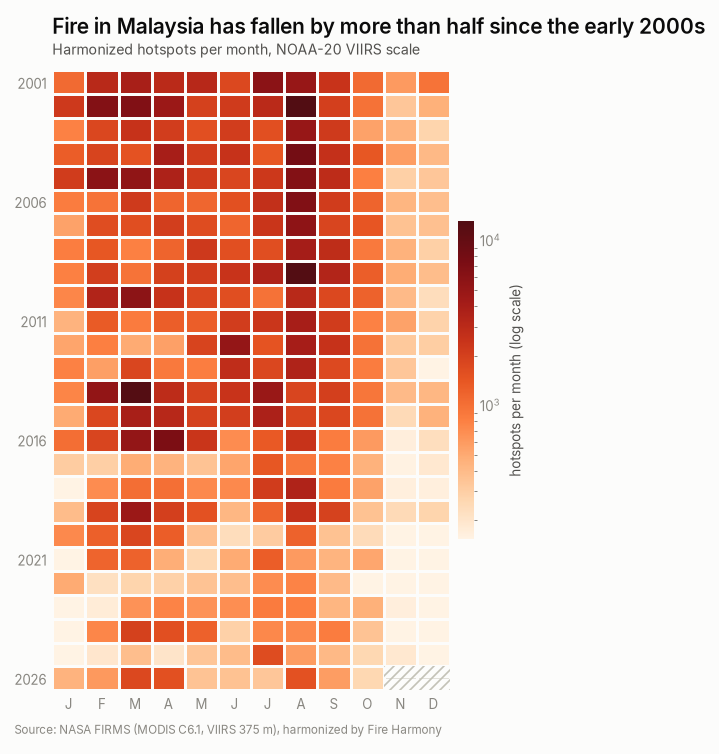

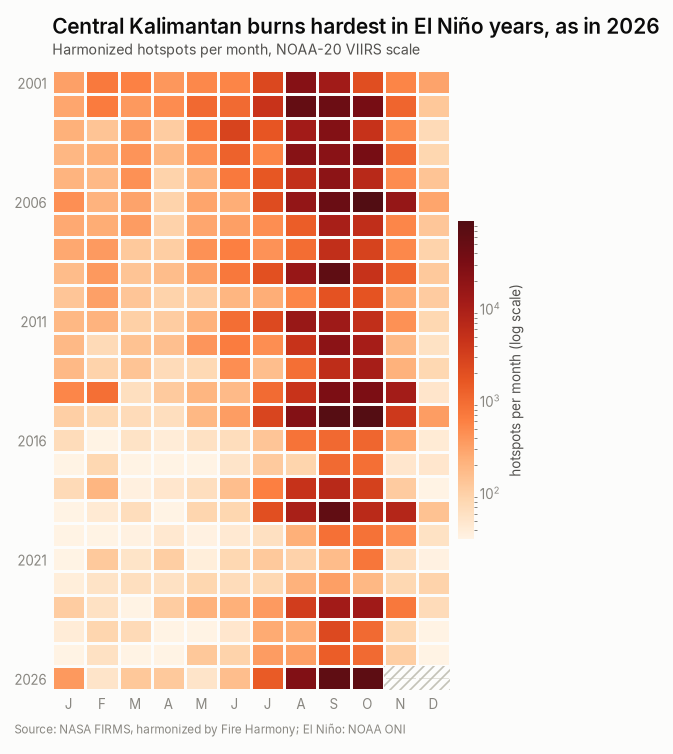

In [2]:
def calendar(ax, s, title, sub):
    m = s[s.yr.between(2001, 2026)].pivot(index='yr', columns='mo', values='value')
    v = m.to_numpy()
    vmin = max(1, np.nanpercentile(v[v > 0], 5))
    shown = np.where(np.isnan(v), np.nan, np.maximum(v, vmin))          # zero fire: the lightest colour, not blank
    mesh = ax.pcolormesh(np.arange(13), np.arange(len(m) + 1), shown, cmap='ember',
                         norm=LogNorm(vmin=vmin, vmax=np.nanmax(v)), edgecolors=fh.SURFACE, linewidth=1.5)
    for i, j in zip(*np.where(np.isnan(v))):                             # unknown months (no data yet): hatched
        ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, hatch='////', edgecolor=fh.BASELINE, lw=0))
    ax.set_xticks(np.arange(12) + 0.5, list('JFMAMJJASOND')); ax.set_yticks(np.arange(len(m))[::5] + 0.5, m.index[::5])
    ax.invert_yaxis(); ax.tick_params(length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
    fh.title(ax, title, sub)
    return mesh
fig, ax = plt.subplots(figsize=(110 * fh.MM, 150 * fh.MM))
mesh = calendar(ax, series['Malaysia'], 'Fire in Malaysia has fallen by more than half since the early 2000s', 'Harmonized hotspots per month, NOAA-20 VIIRS scale')
cb = fig.colorbar(mesh, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False); cb.set_label('hotspots per month (log scale)', fontsize=8, color=fh.INK_2)
fh.source(fig, 'Source: NASA FIRMS (MODIS C6.1, VIIRS 375 m), harmonized by Fire Harmony')
fig.get_layout_engine().set(rect=(0, 0.035, 1, 1))   # room for the source line
fh.save(fig, FIG / 'fig10_calendar_malaysia')
fig, ax = plt.subplots(figsize=(110 * fh.MM, 150 * fh.MM))
mesh = calendar(ax, series['Central Kalimantan (Indonesia)'], 'Central Kalimantan burns hardest in El Niño years, as in 2026', 'Harmonized hotspots per month, NOAA-20 VIIRS scale')
cb = fig.colorbar(mesh, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False); cb.set_label('hotspots per month (log scale)', fontsize=8, color=fh.INK_2)
fh.source(fig, 'Source: NASA FIRMS, harmonized by Fire Harmony; El Niño: NOAA ONI')
fig.get_layout_engine().set(rect=(0, 0.035, 1, 1))   # room for the source line
fh.save(fig, FIG / 'fig12_calendar_central_kalimantan')

## 2. The normal season and the critical period

The line is the median of each calendar month from 2001 to 2025. The band holds the middle half of the years.

,area,critical period (months),fire year starts in month
0,Malaysia,[8],1
1,Riau (Indonesia),"[7, 8]",1
2,Central Kalimantan (Indonesia),"[8, 9, 10]",1


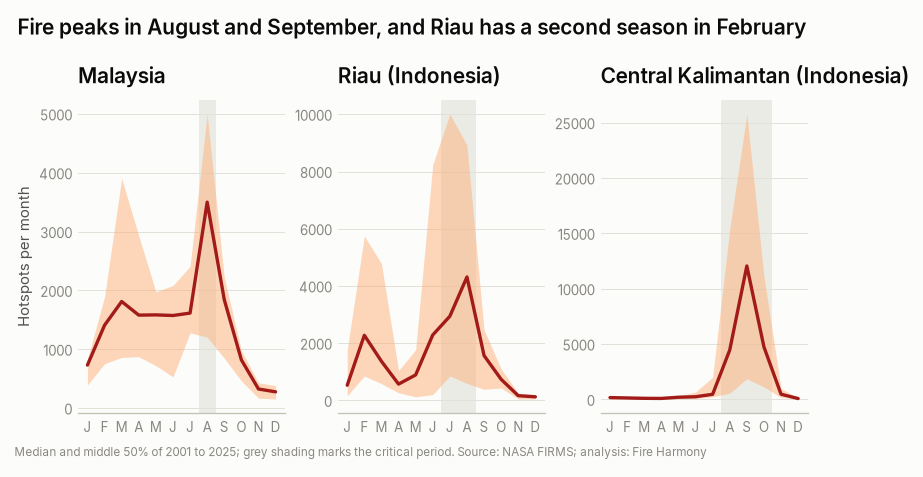

In [3]:
fig, axes = plt.subplots(1, 3, figsize=fh.SIZE['full'], sharex=True)
rows = []
for ax, (name, s) in zip(axes, series.items()):
    clim = A.climatology(s); crit = A.critical(s)
    ax.fill_between(clim.index, clim.q25, clim.q75, color=fh.EMBER[2], alpha=0.5, lw=0)
    ax.plot(clim.index, clim['median'], color=fh.EMBER[6], lw=2)
    for m in crit['critical_period']:
        ax.axvspan(m - 0.5, m + 0.5, color=fh.GRID, alpha=0.6, lw=0, zorder=0)
    ax.set_xticks(range(1, 13), list('JFMAMJJASOND')); fh.clean(ax); fh.title(ax, name)
    rows.append({'area': name, 'critical period (months)': crit['critical_period'], 'fire year starts in month': A.fire_year_start(s)})
axes[0].set_ylabel('Hotspots per month')
fig.suptitle('Fire peaks in August and September, and Riau has a second season in February', x=0.01, ha='left', fontsize=12.5, fontweight='semibold')
fh.source(fig, 'Median and middle 50% of 2001 to 2025; grey shading marks the critical period. Source: NASA FIRMS; analysis: Fire Harmony')
fig.get_layout_engine().set(rect=(0, 0.04, 1, 0.93)); fh.save(fig, FIG / 'fig11_normal_season')
pd.DataFrame(rows)

## 3. Is this month unusual?

For the latest months we compare each one with the same month in normal years: the ratio to the median, its percentile and its rank since 2001.

In [4]:
latest = []
for name, s in series.items():
    a = A.anomalies(s)
    latest.append(a.tail(4).assign(area=name)[['area', 'yr', 'mo', 'value', 'ratio_to_normal', 'percentile', 'rank_in_month']])
pd.concat(latest).round(2)

,area,yr,mo,value,ratio_to_normal,percentile,rank_in_month
309,Malaysia,2026,8,1522.00,0.43,28.0,19
310,Malaysia,2026,9,581.68,0.32,20.0,21
311,Malaysia,2026,10,262.84,0.32,12.0,23
312,Malaysia,2026,11,NaN,NaN,NaN,<NA>
309,Riau (Indonesia),2026,8,1543.80,0.36,28.0,19
310,Riau (Indonesia),2026,9,888.74,0.57,32.0,18
311,Riau (Indonesia),2026,10,87.41,0.12,8.0,24
312,Riau (Indonesia),2026,11,NaN,NaN,NaN,<NA>
309,Central Kalimantan (Indonesia),2026,8,26987.12,6.05,96.0,2
310,Central Kalimantan (Indonesia),2026,9,62013.91,5.14,92.0,3


## 4. When does the season start, peak and end?

Start, middle and end are the points where 10%, 50% and 90% of a fire year's hotspots have burned, counted in months from the start of the fire year.

In [5]:
seas = A.season(series['Riau (Indonesia)'])
seas.round(2).tail(10)

,fire_year,start,peak_month,middle,end,total
15,2016,2.36,8,7.19,7.97,15020.80
16,2017,0.77,7,6.42,9.46,2855.65
17,2018,1.56,8,7.33,8.53,10905.37
18,2019,2.13,9,7.75,8.83,30790.64
19,2020,0.72,3,2.37,6.14,4347.24
20,2021,1.30,3,2.56,8.88,2710.18
21,2022,1.45,3,4.73,7.90,1489.07
22,2023,3.34,10,8.08,9.71,2701.73
23,2024,2.25,3,6.67,9.63,2510.77
24,2025,5.51,7,6.65,10.00,3684.75


## 5. Trends

Is fire becoming more or less common? We use the Mann Kendall test, corrected for years that resemble their neighbours, and Sen's slope.

In [6]:
tr = pd.DataFrame({name: A.trend(s) for name, s in series.items()}).T
tr['MODIS alone, % per decade'] = [A.trend(s.assign(value=s.modis_scale))['pct_per_decade'] for s in series.values()]
tr

,years,trend,p,method,sen_slope_per_year,pct_per_decade,"MODIS alone, % per decade"
Malaysia,25,decreasing,0.000029,hamed_rao,-1126.520989,-53.859012,-53.942207
Riau (Indonesia),25,decreasing,0.000597,hamed_rao,-2152.642359,-74.258749,-66.712102
Central Kalimantan (Indonesia),25,decreasing,0.003016,hamed_rao,-2130.267227,-75.83047,-74.269274


## 6. El Niño

El Niño years are dry in South East Asia. The Oceanic Niño Index (ONI) is the sea surface temperature anomaly in the central Pacific; above +0.5 is El Niño, above +1.5 strong.

In [7]:
oni = pd.read_csv(C.raw('climate_indices', 'noaa_oni.txt'), sep=r'\s+')
peak = oni.groupby('YR').ANOM.max().loc[2014:2026]
peak.round(2).rename('highest 3 month ONI').to_frame().T

YR,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
highest 3 month ONI,0.8,2.59,2.5,0.35,1.05,0.99,0.71,-0.31,-0.68,1.99,1.84,0.02,2.46


> **Key findings**
>
> - Each area has a short critical period: August in Malaysia, July and August in Riau, August to October in Central Kalimantan.
> - Riau also has a second, smaller season in February and March.
> - Fire has fallen strongly since 2001: by about 54% per decade in Malaysia, 74% in Riau and 76% in Central Kalimantan. MODIS alone shows a similar fall (54%, 67% and 74%), so the harmonization does not cause it.
> - In 2026, during the strongest El Niño since 2015, Central Kalimantan burned 5 to 14 times more than normal from August to October, ranking second or third since 2001 in each month. Malaysia and Riau stayed below normal.
> - The newest month has only a few days of data, so we show it as not yet known instead of zero.